# Weekly Product-Group Sales Forecasting

## Objective

Predict the number of purchase records for each product group during the
following week.

This can support sales planning and comparisons of purchasing activity
across product groups.

## Target Definition

The target is the weekly count of transaction rows within each product group.

It is not:
- The number of distinct orders, because an order identifier is unavailable.
- Unconstrained demand, because inventory and stockout information are unavailable.
- Revenue or profit.

## Evaluation Approach

- Define weeks as Monday through Sunday.
- Exclude incomplete boundary weeks.
- Use earlier weeks for training and later weeks for evaluation.
- Construct lag and rolling features using past observations only.
- Compare simple forecasting baselines with more advanced models.
- Evaluate with MAE, RMSE, and WAPE where its denominator is nonzero.

Forecasting models will be assessed using time-based splits.

In [1]:
import sys
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the project from either its root or the notebook folder.
current_folder = Path.cwd().resolve()

project_root = next(
    (
        folder
        for folder in [current_folder, *current_folder.parents]
        if (folder / "data" / "processed" / "transactions.parquet").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate data/processed/transactions.parquet. "
        "Open this notebook inside your project folder."
    )

data_dir = project_root / "data" / "processed"
forecast_report_dir = project_root / "reports" / "forecasting"
forecast_report_dir.mkdir(parents=True, exist_ok=True)

source_files = {
    "transactions": data_dir / "transactions.parquet",
    "articles": data_dir / "articles.parquet",
}

for source_name, file_path in source_files.items():
    if not file_path.is_file():
        raise FileNotFoundError(f"Missing {source_name} file: {file_path}")

# A separate connection name avoids replacing the recommendation connection.
if "forecast_con" in globals():
    forecast_con.close()

forecast_con = duckdb.connect()
forecast_con.execute("SET memory_limit = '1GB'")
forecast_con.execute("SET threads = 2")

for view_name, file_path in source_files.items():
    sql_path = file_path.as_posix().replace("'", "''")
    forecast_con.execute(f"""
        CREATE OR REPLACE TEMP VIEW {view_name} AS
        SELECT * FROM read_parquet('{sql_path}')
    """)

print("Python:", sys.executable)
print("Project folder:", project_root)
print("DuckDB version:", duckdb.__version__)
print("Source views ready: transactions, articles")
print("Forecast reports folder:", forecast_report_dir)

# Check date coverage.
forecast_date_check = forecast_con.execute("""
    SELECT
        MIN(t_dat) AS first_transaction_date,
        MAX(t_dat) AS last_transaction_date,
        COUNT(*) AS purchase_records,
        COUNT(*) FILTER (WHERE t_dat IS NULL) AS missing_dates
    FROM transactions
""").df()

display(forecast_date_check)

# Ensure joining article metadata cannot multiply transaction records.
forecast_article_check = forecast_con.execute("""
    SELECT
        COUNT(*) AS article_rows,
        COUNT(DISTINCT article_id) AS unique_article_ids,
        COUNT(*) FILTER (WHERE article_id IS NULL) AS missing_article_ids
    FROM articles
""").df()

display(forecast_article_check)

assert (
    forecast_article_check.loc[0, "article_rows"]
    == forecast_article_check.loc[0, "unique_article_ids"]
), "Article IDs must be unique and nonmissing before joining."

assert int(forecast_date_check.loc[0, "missing_dates"]) == 0, (
    "Missing transaction dates need review before weekly aggregation."
)

print("Forecasting setup checks passed.")

Python: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\.venv\Scripts\python.exe
Project folder: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project
DuckDB version: 1.5.5
Source views ready: transactions, articles
Forecast reports folder: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\reports\forecasting


,first_transaction_date,last_transaction_date,purchase_records,missing_dates
0,2018-09-20,2020-09-22,31788324,0


,article_rows,unique_article_ids,missing_article_ids
0,105542,105542,0


Forecasting setup checks passed.


## 1. Preparing Complete Weekly Sales Totals

Transactions are aggregated into Monday–Sunday weeks.

The first and last partial weeks are excluded so that all modeled weeks
represent seven calendar days.

Article metadata is joined using a left join to preserve transaction rows.
Missing product-group labels are assigned to an explicit fallback group.

Before aggregation, we check for calendar dates without transaction records.
Such dates require review because missing data and genuine zero sales cannot
be distinguished from transaction records alone.

First complete week starts: 2018-09-24
Last complete week ends: 2020-09-20
Calendar dates without transaction records: 0


,complete_week_purchase_records,unmatched_article_records,records_without_product_group
0,31557521,0,0


,complete_weeks,product_groups,first_week_start,last_week_end,total_purchase_records,average_weekly_records,minimum_weekly_records,maximum_weekly_records
0,104,19,2018-09-24,2020-09-20,31557521,303437.7,183656,562990


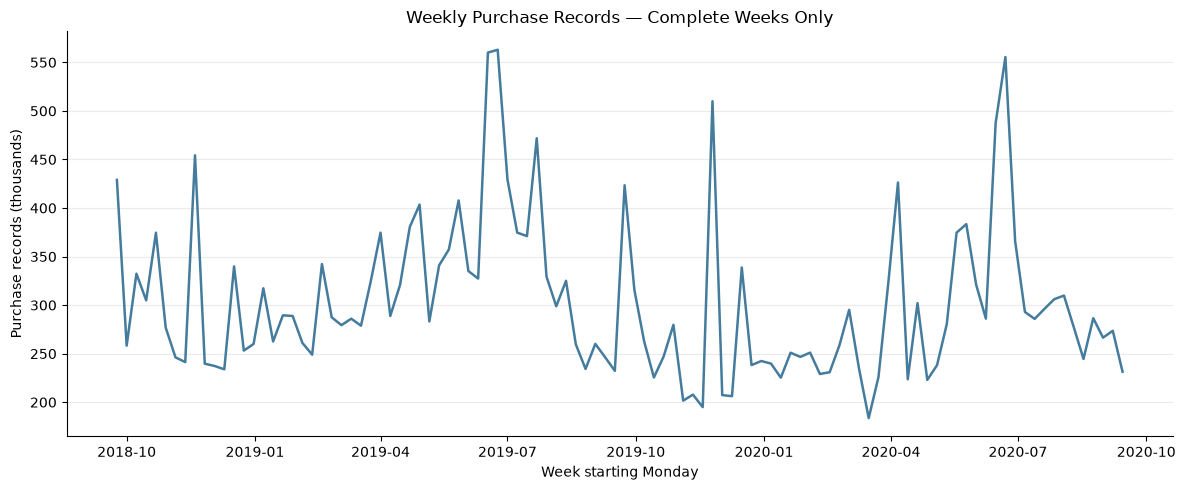

Weekly aggregation and graph saved.


In [2]:
# 1. Identify complete calendar weeks within the observed date range.
first_date = pd.Timestamp(
    forecast_date_check.loc[0, "first_transaction_date"]
).normalize()

last_date = pd.Timestamp(
    forecast_date_check.loc[0, "last_transaction_date"]
).normalize()

first_full_monday = first_date + pd.Timedelta(
    days=(7 - first_date.weekday()) % 7
)

last_full_sunday = last_date - pd.Timedelta(
    days=(last_date.weekday() + 1) % 7
)

first_week_sql = first_full_monday.date().isoformat()
last_day_sql = last_full_sunday.date().isoformat()

print("First complete week starts:", first_week_sql)
print("Last complete week ends:", last_day_sql)

# 2. Check that every calendar date in this interval has transactions.
observed_dates = forecast_con.execute(f"""
    SELECT DISTINCT CAST(t_dat AS DATE) AS transaction_date
    FROM transactions
    WHERE t_dat >= DATE '{first_week_sql}'
      AND t_dat < DATE '{last_day_sql}' + INTERVAL 1 DAY
    ORDER BY transaction_date
""").df()

expected_dates = pd.date_range(
    first_full_monday, last_full_sunday, freq="D"
)

missing_calendar_dates = expected_dates.difference(
    pd.DatetimeIndex(pd.to_datetime(observed_dates["transaction_date"]))
)

print("Calendar dates without transaction records:", len(missing_calendar_dates))

if len(missing_calendar_dates) > 0:
    display(pd.DataFrame({"date_without_records": missing_calendar_dates}))
    raise ValueError(
        "Review dates without records before treating them as zero sales."
    )

# 3. Join article metadata while retaining every transaction row.
forecast_con.execute(f"""
    CREATE OR REPLACE TEMP VIEW forecast_complete_transactions AS
    SELECT
        CAST(t.t_dat AS DATE) AS transaction_date,
        CAST(DATE_TRUNC('week', t.t_dat) AS DATE) AS week_start,
        COALESCE(
            NULLIF(TRIM(a.product_group_name), ''),
            '__MISSING_PRODUCT_GROUP__'
        ) AS product_group_name,
        a.article_id IS NULL AS unmatched_article
    FROM transactions AS t
    LEFT JOIN articles AS a
        ON t.article_id = a.article_id
    WHERE t.t_dat >= DATE '{first_week_sql}'
      AND t.t_dat < DATE '{last_day_sql}' + INTERVAL 1 DAY
""")

join_check = forecast_con.execute("""
    SELECT
        COUNT(*) AS complete_week_purchase_records,
        COUNT(*) FILTER (WHERE unmatched_article) AS unmatched_article_records,
        COUNT(*) FILTER (
            WHERE product_group_name = '__MISSING_PRODUCT_GROUP__'
        ) AS records_without_product_group
    FROM forecast_complete_transactions
""").df()

display(join_check)

# 4. Aggregate observed sales by week and product group.
weekly_group_sales = forecast_con.execute("""
    SELECT
        week_start,
        product_group_name,
        COUNT(*) AS purchase_records
    FROM forecast_complete_transactions
    GROUP BY week_start, product_group_name
    ORDER BY week_start, product_group_name
""").df()

weekly_group_sales["week_start"] = pd.to_datetime(
    weekly_group_sales["week_start"]
)

# Total sales across all groups for the initial overview.
weekly_total_sales = (
    weekly_group_sales.groupby("week_start", as_index=False)["purchase_records"]
    .sum()
    .sort_values("week_start")
)

expected_week_starts = pd.date_range(
    first_full_monday,
    last_full_sunday - pd.Timedelta(days=6),
    freq="W-MON"
)

assert len(weekly_total_sales) == len(expected_week_starts)
assert int(weekly_total_sales["purchase_records"].sum()) == int(
    join_check.loc[0, "complete_week_purchase_records"]
)

weekly_summary = pd.DataFrame([{
    "complete_weeks": len(weekly_total_sales),
    "product_groups": weekly_group_sales["product_group_name"].nunique(),
    "first_week_start": first_full_monday.date(),
    "last_week_end": last_full_sunday.date(),
    "total_purchase_records": int(weekly_total_sales["purchase_records"].sum()),
    "average_weekly_records": weekly_total_sales["purchase_records"].mean(),
    "minimum_weekly_records": weekly_total_sales["purchase_records"].min(),
    "maximum_weekly_records": weekly_total_sales["purchase_records"].max(),
}])

display(weekly_summary.round(2))

# 5. Plot observed weekly sales.
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    weekly_total_sales["week_start"],
    weekly_total_sales["purchase_records"] / 1000,
    color="#457B9D",
    linewidth=1.8
)

ax.set_title("Weekly Purchase Records — Complete Weeks Only")
ax.set_xlabel("Week starting Monday")
ax.set_ylabel("Purchase records (thousands)")
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(
    forecast_report_dir / "weekly_total_purchase_records.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

weekly_group_sales.to_csv(
    forecast_report_dir / "weekly_product_group_observed_sales.csv",
    index=False
)

print("Weekly aggregation and graph saved.")

## 2. Continuous Weekly Series and Chronological Splits

Create one observation per product group per complete calendar week.

A missing group–week combination is filled with zero recorded purchases.
This means no purchases were recorded for that group; it does not establish
that products were available or that customer demand was zero.

The 104 weeks are divided chronologically:
- First 80 weeks: training.
- Next 12 weeks: validation.
- Final 12 weeks: held-out testing.

Models will predict one week ahead. At each forecast origin, only observations
from completed earlier weeks may be used.

Validation results guide model selection. Final-test outcomes must not be
used to choose algorithms, features, or hyperparameters.

Large observed sales peaks are retained unless a data-quality issue is identified.

,split,first_week_start,last_week_start,weeks,group_week_rows,zero_filled_rows,last_week_end
0,train,2018-09-24,2020-03-30,80,1520,320,2020-04-05
1,validation,2020-04-06,2020-06-22,12,228,41,2020-06-28
2,test,2020-06-29,2020-09-14,12,228,36,2020-09-20


,product_group_name,training_purchase_records,weeks_with_sales
7,Garment Upper body,9881895,80
6,Garment Lower body,5302846,80
5,Garment Full body,2483532,80
16,Underwear,1923364,80
15,Swimwear,1710178,80
0,Accessories,1260568,80
12,Shoes,563829,80
13,Socks & Tights,557454,80
11,Nightwear,286592,80
18,Unknown,39315,80


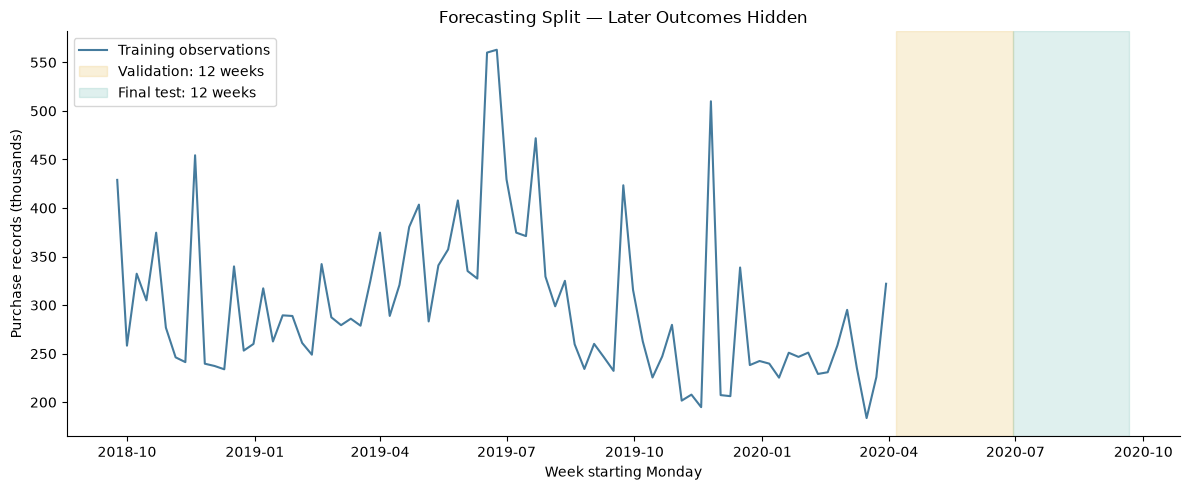

Continuous weekly panel and split definitions saved.
Total group-week rows: 1976
Validation begins: 2020-04-06
Final test begins: 2020-06-29


In [3]:
# 1. Create a complete weekly calendar for each observed product group.
week_calendar = pd.DatetimeIndex(
    expected_week_starts,
    name="week_start"
)

product_groups = sorted(
    weekly_group_sales["product_group_name"].unique()
)

complete_index = pd.MultiIndex.from_product(
    [week_calendar, product_groups],
    names=["week_start", "product_group_name"]
)

observed_series = weekly_group_sales.set_index(
    ["week_start", "product_group_name"]
)["purchase_records"]

assert observed_series.index.is_unique

weekly_panel = observed_series.reindex(complete_index).to_frame()

# Retain an indicator so zero-filled entries remain identifiable.
weekly_panel["filled_zero_records"] = (
    weekly_panel["purchase_records"].isna()
)

weekly_panel["purchase_records"] = (
    weekly_panel["purchase_records"].fillna(0).astype("int64")
)

weekly_panel = weekly_panel.reset_index()

# 2. Fix chronological boundaries.
validation_weeks = 12
test_weeks = 12
training_weeks = len(week_calendar) - validation_weeks - test_weeks

assert training_weeks > 52, "Insufficient history for a 52-week lag baseline."

validation_start = week_calendar[training_weeks]
test_start = week_calendar[training_weeks + validation_weeks]

weekly_panel["split"] = np.select(
    [
        weekly_panel["week_start"] < validation_start,
        weekly_panel["week_start"] < test_start,
    ],
    ["train", "validation"],
    default="test"
)

# 3. Verify that calendar completion did not change recorded sales totals.
assert len(weekly_panel) == len(week_calendar) * len(product_groups)
assert not weekly_panel.duplicated(
    ["week_start", "product_group_name"]
).any()
assert weekly_panel["purchase_records"].notna().all()
assert (weekly_panel["purchase_records"] >= 0).all()
assert int(weekly_panel["purchase_records"].sum()) == int(
    weekly_group_sales["purchase_records"].sum()
)

split_summary = (
    weekly_panel.groupby("split")
    .agg(
        first_week_start=("week_start", "min"),
        last_week_start=("week_start", "max"),
        weeks=("week_start", "nunique"),
        group_week_rows=("purchase_records", "size"),
        zero_filled_rows=("filled_zero_records", "sum"),
    )
    .reindex(["train", "validation", "test"])
    .reset_index()
)

split_summary["last_week_end"] = (
    split_summary["last_week_start"] + pd.Timedelta(days=6)
)

display(split_summary)

# Identify groups without any training sales.
# These need fallback handling rather than fitting a model to future activity.
training_group_summary = (
    weekly_panel.loc[weekly_panel["split"] == "train"]
    .groupby("product_group_name", as_index=False)
    .agg(
        training_purchase_records=("purchase_records", "sum"),
        weeks_with_sales=("purchase_records", lambda x: int((x > 0).sum())),
    )
    .sort_values("training_purchase_records", ascending=False)
)

display(training_group_summary)

# 4. Plot training data only, keeping later outcomes out of model exploration.
training_totals = (
    weekly_panel.loc[weekly_panel["split"] == "train"]
    .groupby("week_start")["purchase_records"]
    .sum()
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    training_totals.index,
    training_totals.values / 1000,
    color="#457B9D",
    label="Training observations"
)

ax.axvspan(
    validation_start, test_start,
    color="#E9C46A", alpha=0.25,
    label="Validation: 12 weeks"
)
ax.axvspan(
    test_start, week_calendar[-1] + pd.Timedelta(days=7),
    color="#2A9D8F", alpha=0.15,
    label="Final test: 12 weeks"
)

ax.set_title("Forecasting Split — Later Outcomes Hidden")
ax.set_xlabel("Week starting Monday")
ax.set_ylabel("Purchase records (thousands)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(
    forecast_report_dir / "chronological_forecasting_split.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

weekly_panel.to_csv(
    forecast_report_dir / "weekly_product_group_panel.csv",
    index=False
)
split_summary.to_csv(
    forecast_report_dir / "forecast_split_summary.csv",
    index=False
)

print("Continuous weekly panel and split definitions saved.")
print("Total group-week rows:", len(weekly_panel))
print("Validation begins:", validation_start.date())
print("Final test begins:", test_start.date())

## 3. One-Week-Ahead Forecasting Baselines

Three baselines are evaluated on the 12 validation weeks:

1. Last-week sales.
2. Mean sales over the previous four completed weeks.
3. Sales from 52 weeks earlier.

Each forecast uses only observations available before its target week.
After a validation week ends, its actual sales may inform subsequent forecasts.

All 19 groups are retained, including groups with no training sales.
No final-test outcomes are used in this comparison.

### Metrics

- MAE: average absolute error per product-group week.
- RMSE: gives larger errors more weight.
- WAPE: total absolute error divided by total actual sales, expressed as a percentage.

Lower values are better. WAPE emphasizes high-volume groups and is not
classification accuracy. Group-level results will also be examined.

,model,evaluated_group_weeks,MAE,RMSE,WAPE_pct
0,Last week,228,"4,456.11","10,874.40",24.77%
1,Four-week average,228,"4,773.21","11,253.49",26.53%
2,Seasonal naive (52 weeks),228,"4,061.26","9,815.75",22.57%


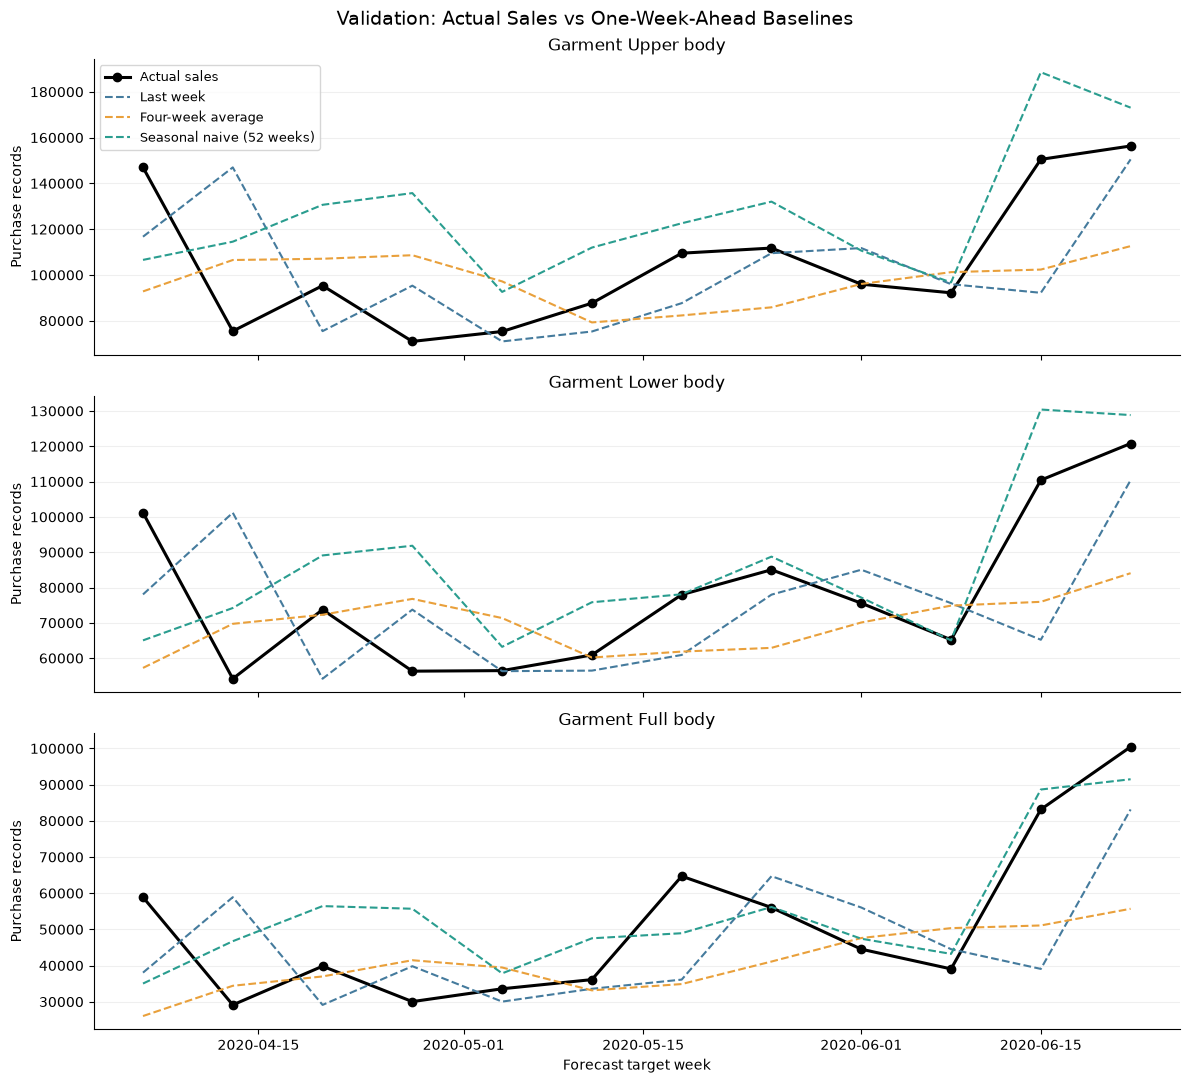

Baseline validation metrics, predictions, and graph saved.


In [4]:
# Work only with training and validation observations at this stage.
baseline_data = (
    weekly_panel.loc[weekly_panel["split"] != "test"]
    .copy()
    .sort_values(["product_group_name", "week_start"])
    .reset_index(drop=True)
)

grouped_sales = baseline_data.groupby(
    "product_group_name", sort=False
)["purchase_records"]

# Shift first so the target week's actual sales never enter its forecast.
baseline_data["last_week"] = grouped_sales.shift(1)

baseline_data["four_week_average"] = grouped_sales.transform(
    lambda sales: sales.shift(1).rolling(
        window=4, min_periods=4
    ).mean()
)

baseline_data["seasonal_naive_52w"] = grouped_sales.shift(52)

baseline_columns = {
    "Last week": "last_week",
    "Four-week average": "four_week_average",
    "Seasonal naive (52 weeks)": "seasonal_naive_52w",
}

validation_baselines = baseline_data.loc[
    baseline_data["split"] == "validation"
].copy()

assert len(validation_baselines) == 12 * len(product_groups)
assert validation_baselines[list(baseline_columns.values())].notna().all().all()

# Reusable metric function for later models.
def calculate_forecast_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    if actual.shape != predicted.shape:
        raise ValueError("Actual and predicted arrays must have matching shapes.")
    if not (np.isfinite(actual).all() and np.isfinite(predicted).all()):
        raise ValueError("Actual values and predictions must be finite.")

    errors = predicted - actual
    absolute_errors = np.abs(errors)
    denominator = np.abs(actual).sum()

    return {
        "MAE": absolute_errors.mean(),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "WAPE_pct": (
            100 * absolute_errors.sum() / denominator
            if denominator > 0 else np.nan
        ),
    }

# Overall metrics across all 228 product-group weeks.
baseline_metric_rows = []

for model_name, prediction_column in baseline_columns.items():
    baseline_metric_rows.append({
        "model": model_name,
        "evaluated_group_weeks": len(validation_baselines),
        **calculate_forecast_metrics(
            validation_baselines["purchase_records"],
            validation_baselines[prediction_column]
        )
    })

baseline_validation_results = pd.DataFrame(baseline_metric_rows)

display(
    baseline_validation_results.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "WAPE_pct": "{:.2f}%",
    })
)

# Preserve per-group results to inspect small and intermittent groups later.
group_metric_rows = []

for group_name, group_data in validation_baselines.groupby("product_group_name"):
    for model_name, prediction_column in baseline_columns.items():
        group_metric_rows.append({
            "product_group_name": group_name,
            "model": model_name,
            "actual_validation_records": int(
                group_data["purchase_records"].sum()
            ),
            **calculate_forecast_metrics(
                group_data["purchase_records"],
                group_data[prediction_column]
            )
        })

baseline_group_results = pd.DataFrame(group_metric_rows)

# Plot the three largest groups, selected using TRAINING sales only.
plot_groups = training_group_summary.head(3)["product_group_name"].tolist()

fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)

for ax, group_name in zip(axes, plot_groups):
    group_data = validation_baselines.loc[
        validation_baselines["product_group_name"] == group_name
    ].sort_values("week_start")

    ax.plot(
        group_data["week_start"],
        group_data["purchase_records"],
        color="black",
        linewidth=2.2,
        marker="o",
        label="Actual sales"
    )

    for (model_name, prediction_column), color in zip(
        baseline_columns.items(),
        ["#457B9D", "#E9A03B", "#2A9D8F"]
    ):
        ax.plot(
            group_data["week_start"],
            group_data[prediction_column],
            color=color,
            linestyle="--",
            label=model_name
        )

    ax.set_title(group_name)
    ax.set_ylabel("Purchase records")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].legend(fontsize=9)
axes[-1].set_xlabel("Forecast target week")
fig.suptitle("Validation: Actual Sales vs One-Week-Ahead Baselines", fontsize=14)
fig.tight_layout()

fig.savefig(
    forecast_report_dir / "baseline_validation_forecasts.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

baseline_validation_results.to_csv(
    forecast_report_dir / "baseline_validation_metrics.csv",
    index=False
)
baseline_group_results.to_csv(
    forecast_report_dir / "baseline_validation_metrics_by_group.csv",
    index=False
)
validation_baselines.to_csv(
    forecast_report_dir / "baseline_validation_predictions.csv",
    index=False
)

print("Baseline validation metrics, predictions, and graph saved.")

In [5]:
display(
    baseline_validation_results
    .sort_values("WAPE_pct")
    .reset_index(drop=True)
    .round(2)
)

,model,evaluated_group_weeks,MAE,RMSE,WAPE_pct
0,Seasonal naive (52 weeks),228,4061.26,9815.75,22.57
1,Last week,228,4456.11,10874.40,24.77
2,Four-week average,228,4773.21,11253.49,26.53


### Findings: Forecasting Baselines

The 52-week seasonal-naive method achieved the lowest validation errors:
MAE of 4,061.26 purchase records per product-group week, RMSE of 9,815.75,
and WAPE of 22.57%.

It outperformed both the last-week and four-week-average baselines.
This suggests that annual timing contains useful forecasting information
during the validation period.

The seasonal-naive method becomes the benchmark for subsequent models.
Performance varies across groups, and aggregate WAPE is influenced most
strongly by high-volume groups.

WAPE is an error measure and must not be converted into classification accuracy.

In [6]:
from importlib import util, metadata

if util.find_spec("statsmodels") is None:
    print("statsmodels: NOT INSTALLED")
else:
    print("statsmodels:", metadata.version("statsmodels"))

statsmodels: NOT INSTALLED


In [8]:
!pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ------ --------------------------------- 1.8/11.3 MB 17.3 MB/s eta 0:00:01
   ------------- -------------------------- 3.9/11.3 MB 12.5 MB/s eta 0:00:01
   ------------------- -------------------- 5.5/11.3 MB 10.3 MB/s eta 0:00:01
   ----------------------- ---------------- 6.6/11.3 MB 8.9 MB/s eta 0:00:01
   -------------------------- ------------- 7.6/11.3 MB 8.1 MB/s eta 0:00:01
   ------------------------------ --------- 8.7/11.3 MB 7.6 MB/s eta 0:00:01
   -------------------------------- ------- 9.2/11.3 MB 7.1 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.3 MB 6.8 MB/s eta 0:00:01
   ---------------------------------- ----- 9.7/11.3 MB 5.9 MB/s eta 0:00:01
   ----------------------------------- ---- 10.0/11.3 MB 5.3 MB/s eta 0:00:01
   ------------------------------------ --- 10.2/11.3 MB 4.9 MB/s eta 0:00:01
   ------------------------------------ --- 10.5/11.3 MB 4.6 MB/s eta 0:00:01


## 4. Exponential-Smoothing Forecasts

Compare level-only exponential smoothing and an additive damped-trend model.

For each product group and validation week:
1. Use only completed earlier weeks.
2. Fit the model on this expanding history.
3. Forecast the next week.
4. Reveal that week's actual sales before forecasting the subsequent week.

These models do not include an annual seasonal component.
The 52-week seasonal-naive baseline remains in the comparison.

Constant histories use their constant value directly.
Failed or nonconverged fits use the previous week's sales as an explicit fallback.
Negative forecasts are clipped to zero, and these adjustments are recorded.

Validation metrics include all groups and all fallback predictions.

Completed: Accessories
Completed: Bags
Completed: Cosmetic
Completed: Fun
Completed: Furniture
Completed: Garment Full body
Completed: Garment Lower body
Completed: Garment Upper body
Completed: Garment and Shoe care
Completed: Interior textile
Completed: Items
Completed: Nightwear
Completed: Shoes
Completed: Socks & Tights
Completed: Stationery
Completed: Swimwear
Completed: Underwear
Completed: Underwear/nightwear
Completed: Unknown


,model,evaluated_group_weeks,MAE,RMSE,WAPE_pct
0,Seasonal naive (52 weeks),228,4061.26,9815.75,22.57
1,Last week,228,4456.11,10874.40,24.77
2,Level-only smoothing,228,4638.71,10935.16,25.78
3,Damped-trend smoothing,228,4722.26,11090.06,26.25
4,Four-week average,228,4773.21,11253.49,26.53


,model,fit_status,forecasts
0,Damped-trend smoothing,constant_history,17
1,Damped-trend smoothing,fitted,211
2,Level-only smoothing,constant_history,17
3,Level-only smoothing,fitted,211


Negative forecasts clipped: 1


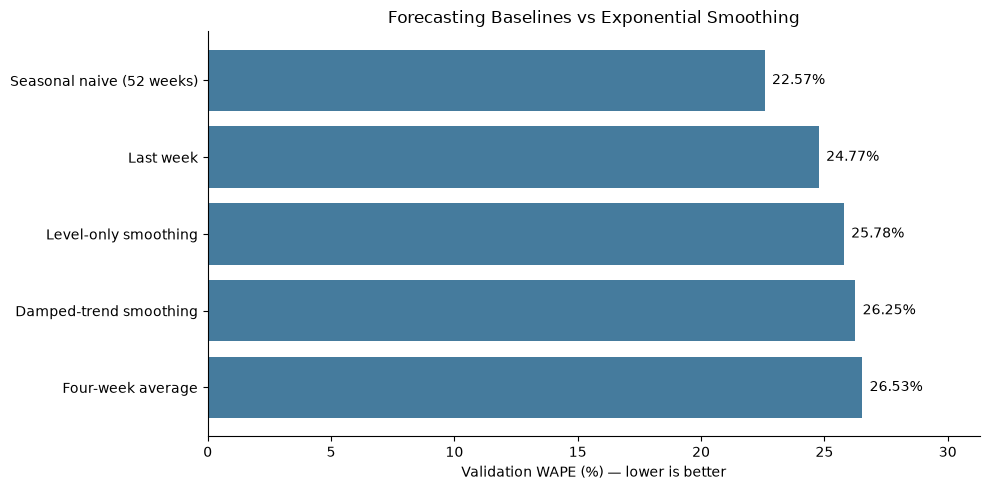

Completed in 5.7 seconds.


In [10]:
import time
import warnings

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tools.sm_exceptions import ConvergenceWarning

smoothing_specs = {
    "Level-only smoothing": {"trend": None, "damped_trend": False},
    "Damped-trend smoothing": {"trend": "add", "damped_trend": True},
}

# Exclude final-test observations entirely.
smoothing_data = (
    weekly_panel.loc[weekly_panel["split"] != "test"]
    .sort_values(["product_group_name", "week_start"])
    .copy()
)

smoothing_rows = []
started = time.perf_counter()

for group_name, group_data in smoothing_data.groupby("product_group_name"):
    group_data = group_data.sort_values("week_start").reset_index(drop=True)
    sales = group_data["purchase_records"].to_numpy(dtype=float)

    validation_positions = np.flatnonzero(
        group_data["split"].to_numpy() == "validation"
    )

    for position in validation_positions:
        history = sales[:position]  # Excludes the target week's sales.
        target_week = group_data.loc[position, "week_start"]

        for model_name, specification in smoothing_specs.items():
            status = "fitted"
            warning_text = ""
            clipped = False

            if np.all(history == history[0]):
                prediction = float(history[-1])
                status = "constant_history"
            else:
                # Scale using past observations only for numerical stability.
                scale = max(float(history.mean()), 1.0)

                try:
                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter("always")

                        fitted = ExponentialSmoothing(
                            history / scale,
                            seasonal=None,
                            initialization_method="estimated",
                            **specification
                        ).fit(optimized=True, use_brute=True)

                        raw_prediction = (
                            float(np.asarray(fitted.forecast(1))[0]) * scale
                        )

                    warning_text = " | ".join(
                        str(w.message) for w in caught
                    )

                    convergence_warning = any(
                        issubclass(w.category, ConvergenceWarning)
                        for w in caught
                    )
                    optimizer_ok = bool(
                        getattr(fitted, "mle_retvals", {}).get("success", True)
                    )

                    if convergence_warning or not optimizer_ok:
                        raise RuntimeError("Optimizer did not converge.")
                    if not np.isfinite(raw_prediction):
                        raise ValueError("Forecast is not finite.")

                    clipped = raw_prediction < 0
                    prediction = max(0.0, raw_prediction)

                except (ValueError, RuntimeError, FloatingPointError,
                        np.linalg.LinAlgError) as error:
                    prediction = float(history[-1])
                    status = "last_week_fallback"
                    warning_text = f"{warning_text} | {error}".strip(" |")

            smoothing_rows.append({
                "product_group_name": group_name,
                "week_start": target_week,
                "model": model_name,
                "actual": float(sales[position]),
                "prediction": prediction,
                "fit_status": status,
                "negative_forecast_clipped": clipped,
                "fit_notes": warning_text,
            })

    print(f"Completed: {group_name}")

smoothing_predictions = pd.DataFrame(smoothing_rows)

# Verify complete evaluation coverage.
expected_rows_per_model = len(validation_baselines)

assert not smoothing_predictions.duplicated(
    ["model", "product_group_name", "week_start"]
).any()

assert (
    smoothing_predictions.groupby("model").size()
    == expected_rows_per_model
).all()

assert np.isfinite(smoothing_predictions["prediction"]).all()

# Compare with all three baselines.
smoothing_metric_rows = []

for model_name, model_data in smoothing_predictions.groupby("model"):
    smoothing_metric_rows.append({
        "model": model_name,
        "evaluated_group_weeks": len(model_data),
        **calculate_forecast_metrics(
            model_data["actual"], model_data["prediction"]
        )
    })

smoothing_validation_results = pd.DataFrame(smoothing_metric_rows)

forecast_validation_comparison = pd.concat(
    [baseline_validation_results, smoothing_validation_results],
    ignore_index=True
).sort_values("WAPE_pct").reset_index(drop=True)

display(forecast_validation_comparison.round(2))

# Show whether either method required fallback.
display(
    smoothing_predictions.groupby(["model", "fit_status"])
    .size()
    .reset_index(name="forecasts")
)

print(
    "Negative forecasts clipped:",
    int(smoothing_predictions["negative_forecast_clipped"].sum())
)

# Simple comparison chart.
plot_results = forecast_validation_comparison.sort_values(
    "WAPE_pct", ascending=False
)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(
    plot_results["model"],
    plot_results["WAPE_pct"],
    color="#457B9D"
)

for bar, value in zip(bars, plot_results["WAPE_pct"]):
    ax.text(
        value + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center"
    )

ax.set_xlim(0, plot_results["WAPE_pct"].max() * 1.18)
ax.set_xlabel("Validation WAPE (%) — lower is better")
ax.set_title("Forecasting Baselines vs Exponential Smoothing")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(
    forecast_report_dir / "smoothing_validation_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

smoothing_predictions.to_csv(
    forecast_report_dir / "smoothing_validation_predictions.csv",
    index=False
)
forecast_validation_comparison.to_csv(
    forecast_report_dir / "forecast_validation_comparison.csv",
    index=False
)

print(f"Completed in {time.perf_counter() - started:,.1f} seconds.")

### Findings: Exponential Smoothing

Level-only smoothing achieved 25.78% validation WAPE, while damped-trend
smoothing achieved 26.25%. Both performed worse than the seasonal-naive
benchmark at 22.57%.

Each smoothing method produced 211 fitted forecasts and 17 constant-history
forecasts, with no failed-fit fallbacks. One negative forecast was clipped to zero.

These nonseasonal models did not improve validation performance.
The next experiment combines recent sales history, annual lags, and calendar
information in a machine-learning forecasting model.

## 5. Preparing Features for Machine-Learning Forecasts

A shared forecasting model will learn from multiple product groups.

Predictors include historical sales lags, past rolling averages and variability,
calendar features, and product-group identity.

All sales-based predictors are shifted so that the target week's purchases
cannot enter its features. Calendar features are known before the week begins.

The final-test period remains excluded during development.
Rows without sufficient historical lags are excluded from model training;
all validation rows must have complete features.

Using a 52-week lag leaves 28 usable training weeks per group.
This small training sample favors restrained model complexity.

In [11]:
# Prepare training and validation features only.
ml_forecast_data = (
    weekly_panel.loc[weekly_panel["split"] != "test"]
    .copy()
    .sort_values(["product_group_name", "week_start"])
    .reset_index(drop=True)
)

sales_by_group = ml_forecast_data.groupby(
    "product_group_name", sort=False
)["purchase_records"]

# Historical sales at specific offsets.
forecast_lags = [1, 2, 4, 8, 13, 26, 52]

for lag in forecast_lags:
    ml_forecast_data[f"lag_{lag}"] = sales_by_group.shift(lag)

# Rolling features exclude the target week's sales.
for window in [4, 13]:
    ml_forecast_data[f"rolling_mean_{window}"] = sales_by_group.transform(
        lambda sales: sales.shift(1).rolling(
            window=window, min_periods=window
        ).mean()
    )

ml_forecast_data["rolling_std_4"] = sales_by_group.transform(
    lambda sales: sales.shift(1).rolling(
        window=4, min_periods=4
    ).std(ddof=0)
)

# Calendar features are known at the time of forecasting.
target_dates = ml_forecast_data["week_start"]
annual_phase = (
    2 * np.pi * (target_dates.dt.dayofyear.to_numpy() - 1) / 365.25
)

ml_forecast_data["annual_sin"] = np.sin(annual_phase)
ml_forecast_data["annual_cos"] = np.cos(annual_phase)
ml_forecast_data["month"] = target_dates.dt.month

forecast_numeric_features = (
    [f"lag_{lag}" for lag in forecast_lags]
    + ["rolling_mean_4", "rolling_mean_13", "rolling_std_4"]
    + ["annual_sin", "annual_cos", "month"]
)

forecast_categorical_features = ["product_group_name"]

forecast_feature_columns = (
    forecast_numeric_features + forecast_categorical_features
)

# Only historical warm-up rows may be dropped.
training_candidates = ml_forecast_data.loc[
    ml_forecast_data["split"] == "train"
].copy()

ml_forecast_train = training_candidates.dropna(
    subset=forecast_feature_columns
).copy()

ml_forecast_validation = ml_forecast_data.loc[
    ml_forecast_data["split"] == "validation"
].copy()

assert not ml_forecast_validation[forecast_feature_columns].isna().any().any()
assert len(ml_forecast_validation) == len(validation_baselines)

for frame in [ml_forecast_train, ml_forecast_validation]:
    assert np.isfinite(
        frame[forecast_numeric_features].to_numpy(dtype=float)
    ).all()

assert (
    ml_forecast_train["week_start"].max()
    < ml_forecast_validation["week_start"].min()
)

feature_preparation_summary = pd.DataFrame([{
    "training_rows": len(ml_forecast_train),
    "training_weeks": ml_forecast_train["week_start"].nunique(),
    "validation_rows": len(ml_forecast_validation),
    "validation_weeks": ml_forecast_validation["week_start"].nunique(),
    "numeric_features": len(forecast_numeric_features),
    "categorical_features": len(forecast_categorical_features),
    "training_warmup_rows_removed": (
        len(training_candidates) - len(ml_forecast_train)
    ),
    "missing_validation_predictors": int(
        ml_forecast_validation[forecast_feature_columns].isna().sum().sum()
    ),
}])

display(feature_preparation_summary)

# Show the inputs for the first validation week of the largest training group.
example_group = training_group_summary.iloc[0]["product_group_name"]

display(
    ml_forecast_validation.loc[
        ml_forecast_validation["product_group_name"] == example_group,
        ["week_start", "product_group_name", "purchase_records"]
        + forecast_numeric_features
    ].head(1)
)

print("Features prepared. No machine-learning forecast model trained yet.")

,training_rows,training_weeks,validation_rows,validation_weeks,numeric_features,categorical_features,training_warmup_rows_removed,missing_validation_predictors
0,532,28,228,12,13,1,988,0


,week_start,product_group_name,purchase_records,lag_1,lag_2,lag_4,lag_8,lag_13,lag_26,lag_52,rolling_mean_4,rolling_mean_13,rolling_std_4,annual_sin,annual_cos,month
724,2020-04-06,Garment Upper body,146987,116715.0,89165.0,92136.0,90756.0,98114.0,129915.0,106585.0,92822.75,97818.230769,15546.743234,0.996751,-0.080549,4


Features prepared. No machine-learning forecast model trained yet.


## 6. Gradient-Boosting Forecast Model

A shared gradient-boosting model predicts weekly purchase-record counts
across product groups.

Initial settings:
- 100 trees
- Learning rate: 0.05
- Maximum tree depth: 2
- Minimum observations per leaf: 10
- Squared-error loss
- Random seed: 42

Product groups are one-hot encoded within the training pipeline.

For each validation week, the pipeline is refitted using only earlier
observations with complete historical features. Earlier validation outcomes
become available only after those weeks have ended.

Negative forecasts are clipped to zero.
The final-test period remains excluded.

,model,evaluated_group_weeks,MAE,RMSE,WAPE_pct
0,Seasonal naive (52 weeks),228,4061.26,9815.75,22.57
1,Last week,228,4456.11,10874.40,24.77
2,Gradient boosting,228,4509.22,10376.20,25.06
3,Level-only smoothing,228,4638.71,10935.16,25.78
4,Damped-trend smoothing,228,4722.26,11090.06,26.25
5,Four-week average,228,4773.21,11253.49,26.53


,target_week,latest_training_target_week,training_rows,predicted_groups
0,2020-04-06,2020-03-30,532,19
1,2020-04-13,2020-04-06,551,19
2,2020-04-20,2020-04-13,570,19
3,2020-04-27,2020-04-20,589,19
4,2020-05-04,2020-04-27,608,19
5,2020-05-11,2020-05-04,627,19
6,2020-05-18,2020-05-11,646,19
7,2020-05-25,2020-05-18,665,19
8,2020-06-01,2020-05-25,684,19
9,2020-06-08,2020-06-01,703,19


Negative forecasts clipped: 0
Completed in 1.8 seconds.


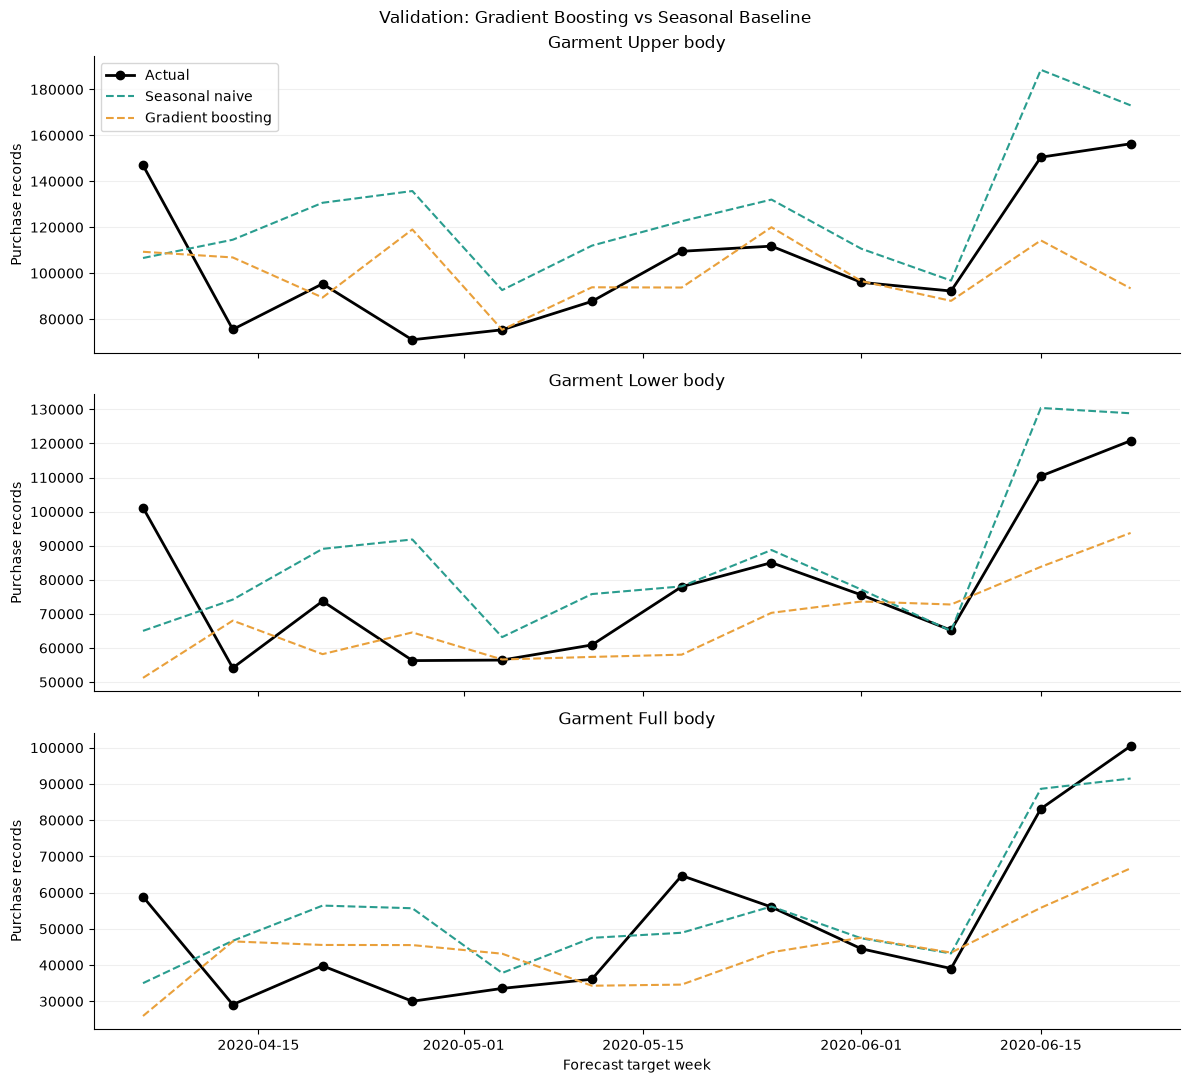

In [12]:
import time

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor

forecast_gb_parameters = {
    "n_estimators": 100,
    "learning_rate": 0.05,
    "max_depth": 2,
    "min_samples_leaf": 10,
    "loss": "squared_error",
    "n_iter_no_change": None,  # No random early-stopping split.
    "random_state": 42,
}

def make_forecast_gb_pipeline():
    preprocessing = ColumnTransformer(
        transformers=[
            ("numeric", "passthrough", forecast_numeric_features),
            (
                "category",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                forecast_categorical_features
            ),
        ]
    )

    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", GradientBoostingRegressor(**forecast_gb_parameters))
    ])

# This pool contains training and validation data only.
# Each forecast selects strictly earlier target dates from the pool.
available_model_rows = ml_forecast_data.dropna(
    subset=forecast_feature_columns
).copy()

assert (available_model_rows["split"] != "test").all()

forecast_gb_batches = []
forecast_gb_audit_rows = []
started = time.perf_counter()

validation_dates = sorted(
    ml_forecast_validation["week_start"].unique()
)

for target_week in validation_dates:
    past_rows = available_model_rows.loc[
        available_model_rows["week_start"] < target_week
    ].copy()

    target_rows = ml_forecast_validation.loc[
        ml_forecast_validation["week_start"] == target_week
    ].copy()

    assert past_rows["week_start"].max() < target_week
    assert len(target_rows) == len(product_groups)

    forecast_gb_model = make_forecast_gb_pipeline()

    forecast_gb_model.fit(
        past_rows[forecast_feature_columns],
        past_rows["purchase_records"]
    )

    raw_predictions = forecast_gb_model.predict(
        target_rows[forecast_feature_columns]
    )

    assert np.isfinite(raw_predictions).all()

    batch = target_rows[
        ["week_start", "product_group_name", "purchase_records"]
    ].rename(columns={"purchase_records": "actual"}).copy()

    batch["prediction"] = np.maximum(raw_predictions, 0.0)
    batch["model"] = "Gradient boosting"
    batch["negative_forecast_clipped"] = raw_predictions < 0

    forecast_gb_batches.append(batch)

    forecast_gb_audit_rows.append({
        "target_week": target_week,
        "latest_training_target_week": past_rows["week_start"].max(),
        "training_rows": len(past_rows),
        "predicted_groups": len(target_rows),
    })

forecast_gb_predictions = pd.concat(
    forecast_gb_batches, ignore_index=True
)
forecast_gb_audit = pd.DataFrame(forecast_gb_audit_rows)

assert len(forecast_gb_predictions) == len(validation_baselines)
assert not forecast_gb_predictions.duplicated(
    ["week_start", "product_group_name"]
).any()

forecast_gb_results = pd.DataFrame([{
    "model": "Gradient boosting",
    "evaluated_group_weeks": len(forecast_gb_predictions),
    **calculate_forecast_metrics(
        forecast_gb_predictions["actual"],
        forecast_gb_predictions["prediction"]
    )
}])

# Rebuild the comparison to avoid duplicate rows when rerunning.
forecast_validation_comparison = pd.concat(
    [
        baseline_validation_results,
        smoothing_validation_results,
        forecast_gb_results
    ],
    ignore_index=True
).sort_values("WAPE_pct").reset_index(drop=True)

display(forecast_validation_comparison.round(2))
display(forecast_gb_audit)

print(
    "Negative forecasts clipped:",
    int(forecast_gb_predictions["negative_forecast_clipped"].sum())
)
print(f"Completed in {time.perf_counter() - started:,.1f} seconds.")

# Compare forecasts for the three largest groups by training sales.
seasonal_comparison = validation_baselines[
    ["week_start", "product_group_name", "seasonal_naive_52w"]
]

plot_data = forecast_gb_predictions.merge(
    seasonal_comparison,
    on=["week_start", "product_group_name"],
    how="left",
    validate="one_to_one"
)

fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)

for ax, group_name in zip(
    axes,
    training_group_summary.head(3)["product_group_name"]
):
    group_data = plot_data.loc[
        plot_data["product_group_name"] == group_name
    ].sort_values("week_start")

    ax.plot(
        group_data["week_start"], group_data["actual"],
        color="black", marker="o", label="Actual", linewidth=2
    )
    ax.plot(
        group_data["week_start"], group_data["seasonal_naive_52w"],
        color="#2A9D8F", linestyle="--", label="Seasonal naive"
    )
    ax.plot(
        group_data["week_start"], group_data["prediction"],
        color="#E9A03B", linestyle="--", label="Gradient boosting"
    )

    ax.set_title(group_name)
    ax.set_ylabel("Purchase records")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].legend()
axes[-1].set_xlabel("Forecast target week")
fig.suptitle("Validation: Gradient Boosting vs Seasonal Baseline")
fig.tight_layout()

fig.savefig(
    forecast_report_dir / "gradient_boosting_validation_forecasts.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

forecast_gb_predictions.to_csv(
    forecast_report_dir / "gradient_boosting_validation_predictions.csv",
    index=False
)
forecast_gb_audit.to_csv(
    forecast_report_dir / "gradient_boosting_training_audit.csv",
    index=False
)
forecast_validation_comparison.to_csv(
    forecast_report_dir / "forecast_validation_comparison.csv",
    index=False
)

### Model Selection

Six forecasting methods were evaluated on the same 228 validation
product-group weeks.

The 52-week seasonal-naive method achieved the lowest MAE, RMSE, and WAPE.
Gradient boosting did not improve on this benchmark with the tested
features and configuration.

Seasonal naïve is selected before examining final-test metrics.
Its forecast for a target week equals the observed purchase-record count
for that product group 52 weeks earlier.

The final test covers 29 June–20 September 2020.
The last-week method is retained as a reference baseline.

Final-test results will be reported without changing the selected method
based on those results.

,model,evaluated_group_weeks,MAE,RMSE,WAPE_pct
0,Seasonal naive (52 weeks),228,3613.04,9319.01,23.97
1,Last week,228,2721.71,7671.71,18.06


,product_group_name,actual_test_records,MAE,RMSE,WAPE_pct
7,Garment Upper body,1291803,24363.92,28221.99,22.63
6,Garment Lower body,747996,13853.83,17970.97,22.23
5,Garment Full body,437002,7693.25,12723.06,21.13
16,Underwear,284463,1906.33,2165.12,8.04
15,Swimwear,284012,12703.83,18568.12,53.68
0,Accessories,177271,1213.58,1641.41,8.22
12,Shoes,72434,1965.25,2316.31,32.56
13,Socks & Tights,69277,1436.58,1740.52,24.88
18,Unknown,37837,2729.42,2777.98,86.56
11,Nightwear,29662,533.17,647.31,21.57


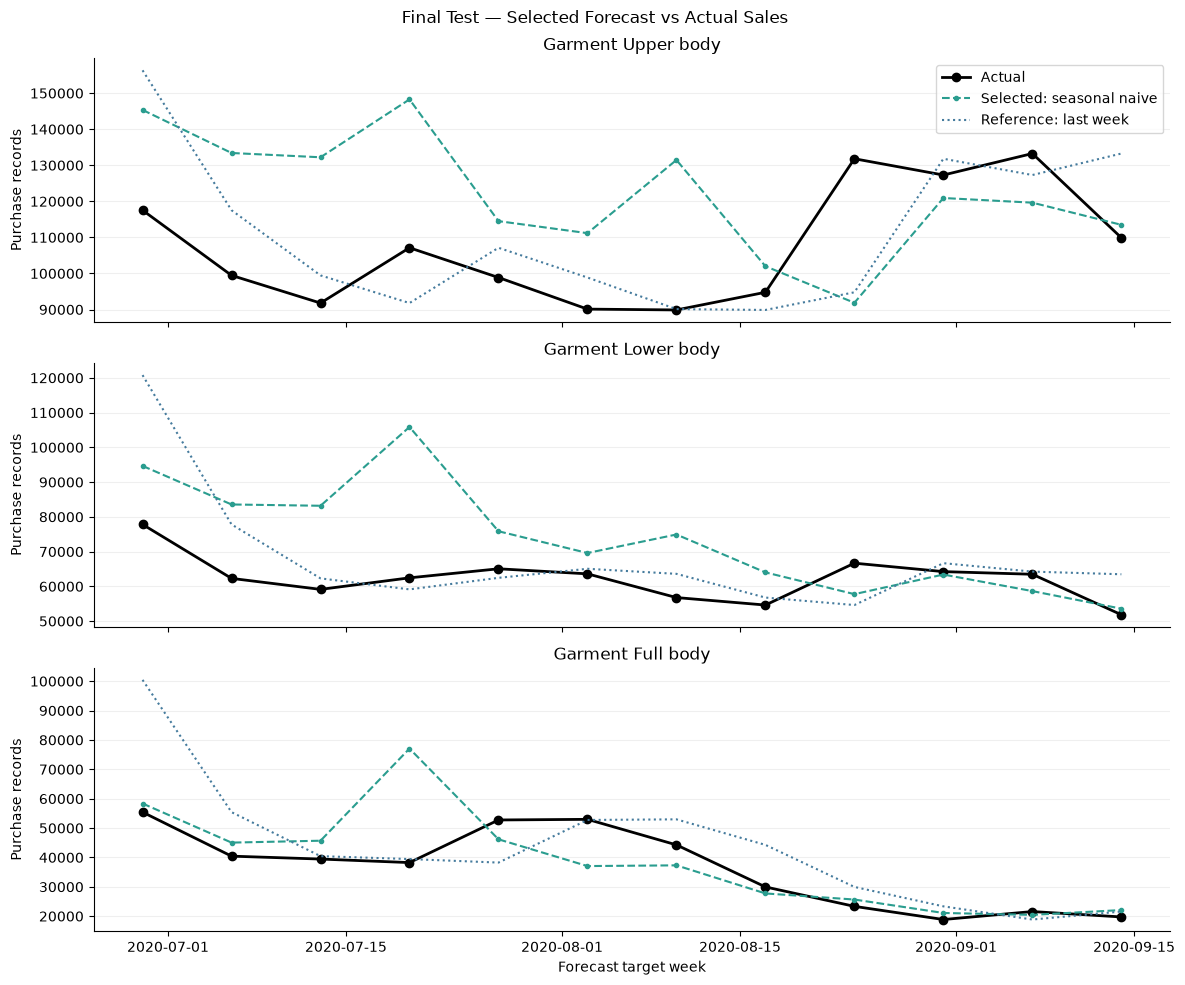

Selected forecasting method: Seasonal naive (52 weeks)
Final-test results, predictions, and graph saved.


In [13]:
# Freeze the selection before calculating test metrics.
selected_forecast_model = "Seasonal naive (52 weeks)"

# Generate strictly historical lags across the complete weekly panel.
final_forecast_data = (
    weekly_panel.copy()
    .sort_values(["product_group_name", "week_start"])
    .reset_index(drop=True)
)

final_grouped_sales = final_forecast_data.groupby(
    "product_group_name", sort=False
)["purchase_records"]

final_forecast_data["selected_prediction"] = final_grouped_sales.shift(52)
final_forecast_data["last_week_prediction"] = final_grouped_sales.shift(1)

forecast_test_predictions = final_forecast_data.loc[
    final_forecast_data["split"] == "test",
    [
        "week_start",
        "product_group_name",
        "purchase_records",
        "selected_prediction",
        "last_week_prediction"
    ]
].rename(columns={"purchase_records": "actual"}).copy()

assert len(forecast_test_predictions) == test_weeks * len(product_groups)
assert forecast_test_predictions[
    ["actual", "selected_prediction", "last_week_prediction"]
].notna().all().all()

# The last-week reference uses observed earlier test weeks as they become
# available. These are rolling one-week-ahead forecasts, not 12-step forecasts.
test_result_rows = []

for model_name, prediction_column in [
    (selected_forecast_model, "selected_prediction"),
    ("Last week", "last_week_prediction")
]:
    test_result_rows.append({
        "model": model_name,
        "evaluated_group_weeks": len(forecast_test_predictions),
        **calculate_forecast_metrics(
            forecast_test_predictions["actual"],
            forecast_test_predictions[prediction_column]
        )
    })

forecast_test_results = pd.DataFrame(test_result_rows)
display(forecast_test_results.round(2))

# Report performance by group as well as the overall metrics.
test_group_rows = []

for group_name, group_data in forecast_test_predictions.groupby(
    "product_group_name"
):
    test_group_rows.append({
        "product_group_name": group_name,
        "actual_test_records": int(group_data["actual"].sum()),
        **calculate_forecast_metrics(
            group_data["actual"],
            group_data["selected_prediction"]
        )
    })

forecast_test_group_results = pd.DataFrame(test_group_rows).sort_values(
    "actual_test_records", ascending=False
)

display(forecast_test_group_results.round(2))

# Plot groups chosen using training sales, not test performance.
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for ax, group_name in zip(
    axes, training_group_summary.head(3)["product_group_name"]
):
    group_data = forecast_test_predictions.loc[
        forecast_test_predictions["product_group_name"] == group_name
    ].sort_values("week_start")

    ax.plot(
        group_data["week_start"], group_data["actual"],
        color="black", marker="o", linewidth=2, label="Actual"
    )
    ax.plot(
        group_data["week_start"], group_data["selected_prediction"],
        color="#2A9D8F", linestyle="--", marker=".",
        label="Selected: seasonal naive"
    )
    ax.plot(
        group_data["week_start"], group_data["last_week_prediction"],
        color="#457B9D", linestyle=":", label="Reference: last week"
    )

    ax.set_title(group_name)
    ax.set_ylabel("Purchase records")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].legend()
axes[-1].set_xlabel("Forecast target week")
fig.suptitle("Final Test — Selected Forecast vs Actual Sales")
fig.tight_layout()

fig.savefig(
    forecast_report_dir / "final_test_forecasts.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

forecast_test_results.to_csv(
    forecast_report_dir / "final_test_metrics.csv", index=False
)
forecast_test_group_results.to_csv(
    forecast_report_dir / "final_test_metrics_by_group.csv", index=False
)
forecast_test_predictions.to_csv(
    forecast_report_dir / "final_test_predictions.csv", index=False
)

print("Selected forecasting method:", selected_forecast_model)
print("Final-test results, predictions, and graph saved.")

### Final-Test Findings and Limitations

Seasonal naïve was selected using validation performance, where it achieved
22.57% WAPE. On the final test, it achieved 23.97% WAPE.

The last-week reference baseline achieved a lower test WAPE of 18.06%,
along with lower MAE and RMSE. Therefore, the validation-selected method
did not retain its advantage in the final-test period.

This result demonstrates that the relative performance of forecasting
methods can vary over time. The available results do not establish the
cause of that variation.

Category-level errors also varied substantially. Seasonal-naive forecasts
performed relatively well for Underwear and Accessories but poorly for
Swimwear and several other groups.

Percentage errors for very small categories should be interpreted alongside
absolute errors. WAPE is undefined when actual sales total zero.

The original model-selection decision and both test results are retained.
Any revised selection strategy requires a new evaluation period.

In [14]:
import json
from datetime import datetime, timezone

forecast_model_dir = project_root / "models" / "forecasting"
forecast_model_dir.mkdir(parents=True, exist_ok=True)

# Seasonal naive has no fitted coefficients.
# Its reusable components are the historical weekly counts and the lag rule.
forecast_history = weekly_panel[
    ["week_start", "product_group_name", "purchase_records"]
].sort_values(["product_group_name", "week_start"]).copy()

history_path = forecast_model_dir / "weekly_history.csv"
forecast_history.to_csv(history_path, index=False)

# Reload and verify the saved history.
reloaded_history = pd.read_csv(
    history_path,
    parse_dates=["week_start"],
    dtype={"product_group_name": "string"}
)

assert len(reloaded_history) == len(forecast_history)
assert not reloaded_history.duplicated(
    ["week_start", "product_group_name"]
).any()
assert int(reloaded_history["purchase_records"].sum()) == int(
    forecast_history["purchase_records"].sum()
)

forecast_validation_comparison.to_csv(
    forecast_model_dir / "validation_model_comparison.csv",
    index=False
)
forecast_test_results.to_csv(
    forecast_model_dir / "final_test_metrics.csv",
    index=False
)
forecast_test_group_results.to_csv(
    forecast_model_dir / "selected_model_test_metrics_by_group.csv",
    index=False
)
forecast_test_predictions.to_csv(
    forecast_model_dir / "final_test_predictions.csv",
    index=False
)

forecast_metadata = {
    "selected_model": selected_forecast_model,
    "selection_basis": "Lowest overall validation WAPE among tested methods",
    "target": "Weekly purchase-record count per product group",
    "week_definition": "Monday through Sunday",
    "forecast_horizon_weeks": 1,
    "seasonal_lag_weeks": 52,
    "forecast_rule": "Prediction for week t equals observed count in week t-52",
    "validation_start": str(validation_start.date()),
    "test_start": str(test_start.date()),
    "last_complete_week_end": str(last_full_sunday.date()),
    "history_scope": (
        "Includes completed training, validation, and test weeks. "
        "Historical replay must enforce the forecast origin."
    ),
    "evaluation_protocol": "Rolling one-week-ahead evaluation",
    "validation_metrics": json.loads(
        forecast_validation_comparison.to_json(orient="records")
    ),
    "test_metrics": json.loads(
        forecast_test_results.to_json(orient="records")
    ),
    "test_conclusion": (
        "The last-week reference outperformed the validation-selected "
        "seasonal-naive method on all three reported test metrics."
    ),
    "limitations": [
        "Observed purchases are not unconstrained demand.",
        "Only two years of weekly history are available.",
        "Performance varies by category and evaluation period.",
        "Missing group-week records were filled with zero recorded purchases.",
        "No inventory, promotion, or stockout predictors are included.",
        "No prediction intervals have been evaluated."
    ],
    "created_at_utc": datetime.now(timezone.utc).isoformat()
}

metadata_path = forecast_model_dir / "metadata.json"
metadata_path.write_text(
    json.dumps(forecast_metadata, indent=2, allow_nan=False),
    encoding="utf-8"
)

print("Saved forecasting files:", forecast_model_dir)
print("Verified weekly history rows:", len(reloaded_history))
print("Saved selection decision:", selected_forecast_model)
print("Both selected-model and reference-baseline test results retained.")

Saved forecasting files: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\models\forecasting
Verified weekly history rows: 1976
Saved selection decision: Seasonal naive (52 weeks)
Both selected-model and reference-baseline test results retained.


## 7. Reusable Forecast Function and Reproducibility

The seasonal-naive function predicts the next Monday–Sunday week using
recorded sales from 52 weeks earlier.

The forecast origin is the Sunday immediately before the target week.
Only weeks completed by that origin are available to the function.

Missing source history raises an error rather than silently becoming zero.
Explicit zero-sales observations remain valid.

Reproducibility is checked against all 228 saved final-test predictions.

In [15]:
import pandas as pd
import numpy as np

def seasonal_naive_forecast(history, forecast_origin, groups=None):
    """Forecast the next complete week using a 52-week seasonal lag."""
    origin = pd.Timestamp(forecast_origin).normalize()

    if origin.weekday() != 6:
        raise ValueError("forecast_origin must be a Sunday.")

    target_week = origin + pd.Timedelta(days=1)
    source_week = target_week - pd.Timedelta(weeks=52)

    data = history[
        ["week_start", "product_group_name", "purchase_records"]
    ].copy()

    data["week_start"] = pd.to_datetime(data["week_start"])

    if data.duplicated(["week_start", "product_group_name"]).any():
        raise ValueError("Duplicate product-group weeks found.")

    if not data["week_start"].dt.weekday.eq(0).all():
        raise ValueError("All week_start dates must be Mondays.")

    # Enforce availability at the historical forecast origin.
    available = data.loc[
        data["week_start"] + pd.Timedelta(days=6) <= origin
    ].copy()

    if groups is None:
        groups = sorted(available["product_group_name"].unique())
    else:
        groups = list(groups)

    if not groups or len(groups) != len(set(groups)):
        raise ValueError("Provide a nonempty list of unique product groups.")

    source = available.loc[
        available["week_start"] == source_week,
        ["product_group_name", "purchase_records"]
    ]

    result = pd.DataFrame({"product_group_name": groups}).merge(
        source,
        on="product_group_name",
        how="left",
        validate="one_to_one"
    )

    if result["purchase_records"].isna().any():
        missing_groups = result.loc[
            result["purchase_records"].isna(), "product_group_name"
        ].tolist()
        raise ValueError(
            f"Missing source history for {source_week.date()}: {missing_groups}"
        )

    values = result["purchase_records"].to_numpy(dtype=float)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Source counts must be finite and nonnegative.")

    result = result.rename(columns={"purchase_records": "prediction"})
    result["forecast_origin"] = origin
    result["week_start"] = target_week
    result["week_end"] = target_week + pd.Timedelta(days=6)
    result["source_week_start"] = source_week

    return result[
        [
            "forecast_origin", "week_start", "week_end",
            "product_group_name", "source_week_start", "prediction"
        ]
    ]


# Reload inputs from disk, rather than using the original prediction objects.
saved_history = pd.read_csv(
    forecast_model_dir / "weekly_history.csv",
    parse_dates=["week_start"]
)

saved_test_predictions = pd.read_csv(
    forecast_model_dir / "final_test_predictions.csv",
    parse_dates=["week_start"]
)

reproduced_batches = []

for target_week, expected in saved_test_predictions.groupby("week_start"):
    reproduced_batches.append(
        seasonal_naive_forecast(
            history=saved_history,
            forecast_origin=target_week - pd.Timedelta(days=1),
            groups=expected["product_group_name"].tolist()
        )
    )

reproduced_test_predictions = pd.concat(
    reproduced_batches, ignore_index=True
)

comparison = saved_test_predictions.merge(
    reproduced_test_predictions[
        ["week_start", "product_group_name", "prediction"]
    ],
    on=["week_start", "product_group_name"],
    how="outer",
    validate="one_to_one",
    indicator=True
)

missing_or_extra = int((comparison["_merge"] != "both").sum())
prediction_mismatches = int(
    (~np.isclose(
        comparison["selected_prediction"],
        comparison["prediction"],
        rtol=0,
        atol=0,
        equal_nan=False
    )).sum()
)

reproduction_summary = pd.DataFrame([{
    "compared_group_weeks": len(comparison),
    "missing_or_extra_rows": missing_or_extra,
    "prediction_mismatches": prediction_mismatches,
}])

display(reproduction_summary)

assert len(comparison) == 228
assert missing_or_extra == 0
assert prediction_mismatches == 0

reproduction_summary.to_csv(
    forecast_report_dir / "forecast_reproduction_check.csv",
    index=False
)

print("PASS: all saved seasonal-naive test predictions reproduced.")

,compared_group_weeks,missing_or_extra_rows,prediction_mismatches
0,228,0,0


PASS: all saved seasonal-naive test predictions reproduced.


In [16]:
import inspect
import importlib.util

forecast_function_path = forecast_model_dir / "forecast_predictor.py"

function_source = inspect.getsource(seasonal_naive_forecast)

forecast_function_path.write_text(
    '"""One-week-ahead seasonal-naive forecasting."""\n\n'
    "import pandas as pd\n"
    "import numpy as np\n\n"
    + function_source,
    encoding="utf-8"
)

# Load the function from the saved Python file.
spec = importlib.util.spec_from_file_location(
    "saved_forecast_predictor",
    forecast_function_path
)
saved_forecast_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(saved_forecast_module)

# Verify the saved implementation across all test weeks.
saved_function_batches = []

for target_week, expected in saved_test_predictions.groupby("week_start"):
    saved_function_batches.append(
        saved_forecast_module.seasonal_naive_forecast(
            history=saved_history,
            forecast_origin=target_week - pd.Timedelta(days=1),
            groups=expected["product_group_name"].tolist()
        )
    )

saved_function_predictions = pd.concat(
    saved_function_batches,
    ignore_index=True
)

saved_function_check = saved_test_predictions.merge(
    saved_function_predictions[
        ["week_start", "product_group_name", "prediction"]
    ],
    on=["week_start", "product_group_name"],
    how="outer",
    validate="one_to_one",
    indicator=True
)

assert len(saved_function_check) == 228
assert saved_function_check["_merge"].eq("both").all()
assert np.array_equal(
    saved_function_check["selected_prediction"].to_numpy(),
    saved_function_check["prediction"].to_numpy()
)

print("Saved reusable function:", forecast_function_path)
print("PASS: imported Python file reproduces all 228 test predictions.")

Saved reusable function: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\models\forecasting\forecast_predictor.py
PASS: imported Python file reproduces all 228 test predictions.


## Forecasting Module Conclusion

Six methods were compared using chronological, one-week-ahead validation.

Seasonal naïve was selected with 22.57% validation WAPE. Its final-test
WAPE was 23.97%, while the last-week reference achieved 18.06%.
The validation-selected method therefore did not outperform the reference
on the final test.

Historical data, configuration, comparison metrics, test predictions,
and a reusable prediction function were saved. All 228 selected-model
test predictions were reproduced from saved inputs.

The module forecasts recorded weekly purchases, not unconstrained demand.
Results vary across product groups and time periods.